# Experiment 9: SVM Hyperparameter Tuning
Run the cells from top to bottom.

In [1]:
# Support Vector Machine (SVM) is a supervised machine learning algorithm used for classification and regression. 
# It finds the best separating boundary, called a hyperplane, between different classes. 
# SVM tries to maintain the maximum margin between the classes to improve classification accuracy.

# Hyperparameter tuning is the process of finding the best values of parameters that control the model's performance. In SVM, important hyperparameters include:
# - C: Controls the trade-off between a wider margin and classification errors. A higher C gives more importance to correctly classifying training data.
# - Gamma: Controls the influence of individual training points when using the RBF kernel.
# - Kernel: Determines the type of decision boundary, such as Linear or RBF.
# GridSearchCV is a hyperparameter tuning technique that tests all specified combinations of parameter values. It uses cross-validation to evaluate each combination and selects the one that gives the best performance.

# In this experiment, a baseline SVM model is first trained using default parameters. Then, GridSearchCV tests different values of C, Gamma and Kernel to find the best combination. Finally, the accuracy of both models is compared using a bar graph.

# Advantages:
# 1. Improves model performance and accuracy.
# 2. Finds suitable hyperparameter values automatically.
# 3. Uses cross-validation for reliable evaluation.
# Limitation: GridSearchCV can be time-consuming when many parameter combinations are tested.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [3]:
# Generate Chess Dataset
np.random.seed(42)
n = 1000
df = pd.DataFrame({
    'Elo_Rating': np.random.randint(2400, 2880, n),
    'Rapid_Rating': np.random.randint(2300, 2850, n),
    'Blitz_Rating': np.random.randint(2300, 2900, n),
    'Age': np.random.randint(16, 48, n),
    'Wins': np.random.randint(0, 15, n),
    'Draws': np.random.randint(2, 20, n),
    'Losses': np.random.randint(0, 10, n)
})
df['Total_Games'] = df.Wins + df.Draws + df.Losses
df['Win_Ratio'] = df.Wins / df.Total_Games

In [4]:
# Create Target Labels
y = np.where((df.Elo_Rating >= 2760) & (df.Win_Ratio >= 0.35), 2,
    np.where((df.Elo_Rating >= 2650) & (df.Win_Ratio >= 0.20), 1, 0))

In [5]:
# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    df, y, test_size=0.2, random_state=42, stratify=y)

In [6]:
# Train Baseline SVM
model = make_pipeline(StandardScaler(), SVC())
model.fit(X_train, y_train)
base = accuracy_score(y_test, model.predict(X_test))

In [7]:
# Tune SVM
grid = GridSearchCV(model, {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': ['scale', 0.01, 0.1, 1],
    'svc__kernel': ['linear', 'rbf']
}, cv=5, n_jobs=-1)
grid.fit(X_train, y_train)
tuned = accuracy_score(y_test, grid.predict(X_test))

In [8]:
# Evaluate Models
print("Baseline Accuracy:", base * 100)
print("Tuned Accuracy:", tuned * 100)
print("Best Parameters:", grid.best_params_)

Baseline Accuracy: 89.0
Tuned Accuracy: 92.0
Best Parameters: {'svc__C': 10, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}


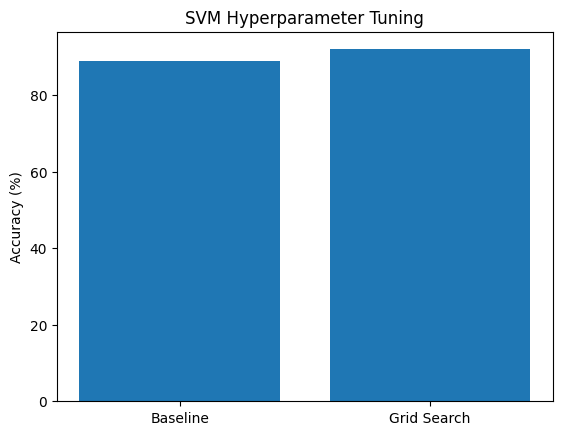

In [9]:
# Compare Accuracy
plt.bar(['Baseline', 'Grid Search'], [base*100, tuned*100])
plt.ylabel("Accuracy (%)")
plt.title("SVM Hyperparameter Tuning")
plt.show()